In [1]:
%load_ext autoreload
%autoreload 2

> **Avant la soutenance :** les sorties enregistrées dans ce notebook proviennent d'une exécution précédente. Redémarrer le noyau et exécuter toutes les cellules dans l'ordre pour mettre à jour les tableaux, graphiques et prédictions avant de reprendre les résultats dans le PowerPoint.

In [2]:
import warnings
warnings.filterwarnings("ignore")
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from script.preprocessing import make_preprocessor, drop_feature_extremes, split_xy
from script.modeling import make_model, NUMERIC_FEATURES, CATEGORICAL_FEATURES


from script.config import TARGET, MAX_FLOORS, SECOND_TARGET
from script.run_cleaning import clean_dataset, save_datasets
from script.clean_rows import audit_rows
from script.clean_columns import drop_leakage_columns
from script.features import build_features, NEW_FEATURES

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Chemin vers le fichier de données fourni
DATA_PATH = "./../data/2016-building-energy-benchmarking.csv"


In [3]:
building_consumption = pd.read_csv(DATA_PATH)
print("Shape brut :", building_consumption.shape)

# Diagnostic des incohérences AVANT nettoyage (ne modifie rien)
display(audit_rows(building_consumption))

# Nettoyage complet (script/run_cleaning.py) : filtres de lignes + traitement des colonnes
df, log = clean_dataset(building_consumption)


Shape brut : (3376, 46)


,nb de lignes
Cible manquante ou <= 0,23
Surface totale <= 0,0
GFA total != Parking + Bâtiment,0
NumberofFloors == 0,16
NumberofFloors > 80,1
NumberofBuildings == 0,92
"YearBuilt hors [1800, 2016]",0
"Surface du plus grand usage > 1,2 x surface totale",86
"Somme des 3 usages > 1,05 x surface totale",503
Plus grand usage manquant,20


Plus grand usage imputé (usage + surface) : 20 lignes concernées (0.6% du jeu), conservées
Surfaces d'usage incohérentes -> GFAInconsistent : 503 lignes concernées (14.9% du jeu), conservées
Colonnes constantes / vides supprimées : ['DataYear', 'City', 'State', 'Comments']
Exclusion Multifamily (BuildingType) : 3376 -> 1668 (-1708 lignes, -50.6% vs précédent, 49.4% du brut restant)
Exclusion Multifamily (colonnes d'usage) : 1668 -> 1629 (-39 lignes, -2.3% vs précédent, 48.3% du brut restant)
Conservation des seuls Compliant : 1629 -> 1510 (-119 lignes, -7.3% vs précédent, 44.7% du brut restant)
Suppression cible manquante ou <= 0 : 1510 -> 1510 (-0 lignes, -0.0% vs précédent, 44.7% du brut restant)
NumberofBuildings = 0 -> NaN + BuildingsMissing : 50 lignes concernées (3.3% du jeu), conservées
NumberofFloors invalide -> NaN + FloorsMissing : 16 lignes concernées (1.1% du jeu), conservées


In [4]:
# Journal du nettoyage : nombre de lignes et % de perte à chaque étape
display(log.to_frame())
print(log.summary())

# Règles qui modifient ou signalent des lignes SANS les supprimer
display(log.touched_frame())

,étape,avant,après,supprimées,% perdu vs étape précédente,% perdu vs brut,% restant vs brut
0,Exclusion Multifamily (BuildingType),3376,1668,1708,50.59,50.59,49.41
1,Exclusion Multifamily (colonnes d'usage),1668,1629,39,2.34,1.16,48.25
2,Conservation des seuls Compliant,1629,1510,119,7.31,3.52,44.73
3,Suppression cible manquante ou <= 0,1510,1510,0,0.00,0.00,44.73


Bilan : 3376 -> 1510 lignes (-1866, soit 55.3% de perte au total, 44.7% conservé)


,règle,lignes concernées,% du jeu
0,Plus grand usage imputé (usage + surface),20,0.59
1,Surfaces d'usage incohérentes -> GFAInconsistent,503,14.90
2,NumberofBuildings = 0 -> NaN + BuildingsMissing,50,3.31
3,NumberofFloors invalide -> NaN + FloorsMissing,16,1.06


## Analyse exploratoire

La cible unique retenue pour la suite du projet est `SiteEnergyUse(kBtu)` (voir `script/config.py`), comme demandé dans les missions 1 et 4. L’analyse porte sur le périmètre nettoyé des bâtiments non résidentiels conformes. Les graphiques utilisent une échelle logarithmique pour rendre lisibles les distributions très asymétriques; les émissions ne sont pas modélisées dans ce parcours.

Périmètre après nettoyage : 1,510 bâtiments, 39 colonnes


,count,mean,std,min,25%,50%,75%,95%,max
SiteEnergyUse(kBtu),1510.0,8923860.92,31667538.43,57133.2,1244409.38,2723303.62,7286407.25,33427000.30,873923712.0
PropertyGFATotal,1510.0,120522.20,307438.82,11285.0,28800.00,48003.50,105775.00,414769.35,9320156.0
PropertyGFABuilding(s),1510.0,106856.57,294191.70,3636.0,27884.00,45970.00,94936.00,365731.20,9320156.0
NumberofFloors,1494.0,4.22,6.35,1.0,1.00,2.00,4.00,13.35,76.0
YearBuilt,1510.0,1961.74,32.53,1900.0,1930.00,1965.50,1988.00,2008.00,2015.0


Asymétrie de SiteEnergyUse(kBtu) : 17.30


,PrimaryPropertyType,Nb_bâtiments,Médiane_kBtu,Médiane_M_kBtu
15,Small- and Mid-Sized Office,278,2.058744e+06,2.058744
8,Other,244,3.485367e+06,3.485367
18,Warehouse,185,1.252324e+06,1.252324
5,Large Office,166,1.322673e+07,13.226733
7,Mixed Use Property,89,2.189735e+06,2.189735
12,Retail Store,85,2.545405e+06,2.545405
2,Hotel,75,6.505995e+06,6.505995
19,Worship Facility,69,8.930532e+05,0.893053
0,Distribution Center,53,1.157976e+06,1.157976
3,K-12 School,50,1.732190e+06,1.732190


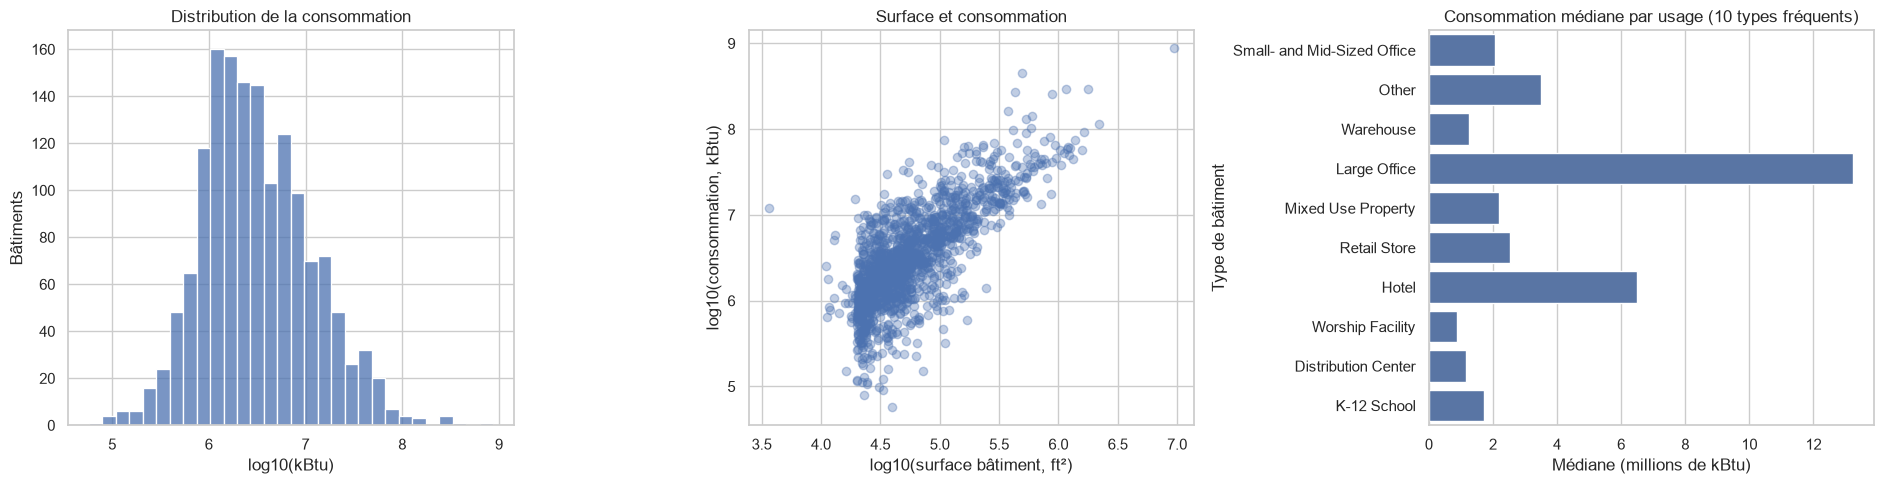

In [5]:
colonnes_eda = [TARGET, 'PropertyGFATotal', 'PropertyGFABuilding(s)', 'NumberofFloors', 'YearBuilt']
print(f'Périmètre après nettoyage : {len(df):,} bâtiments, {df.shape[1]} colonnes')
display(df[colonnes_eda].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T.round(2))
print(f'Asymétrie de {TARGET} : {df[TARGET].skew():.2f}')

profil_usage = (
    df.groupby('PrimaryPropertyType', as_index=False)
      .agg(Nb_bâtiments=(TARGET, 'size'),
           Médiane_kBtu=(TARGET, 'median'))
)
top_usages = profil_usage.nlargest(10, 'Nb_bâtiments').copy()
top_usages['Médiane_M_kBtu'] = top_usages['Médiane_kBtu'] / 1_000_000
display(top_usages.sort_values('Nb_bâtiments', ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.histplot(np.log10(df[TARGET]), bins=30, ax=axes[0])
axes[0].set(title='Distribution de la consommation', xlabel='log10(kBtu)', ylabel='Bâtiments')
axes[1].scatter(np.log10(df['PropertyGFABuilding(s)'].clip(lower=1)),
                np.log10(df[TARGET].clip(lower=1)), alpha=0.35)
axes[1].set(title='Surface et consommation', xlabel='log10(surface bâtiment, ft²)',
            ylabel='log10(consommation, kBtu)')
sns.barplot(data=top_usages, x='Médiane_M_kBtu', y='PrimaryPropertyType', ax=axes[2])
axes[2].set(title='Consommation médiane par usage (10 types fréquents)',
            xlabel='Médiane (millions de kBtu)', ylabel='Type de bâtiment')
plt.tight_layout()
plt.show()

In [6]:
clean_path, model_path = save_datasets(df, "./../data")

Écrit : ./../data\2016-building-energy-benchmarking-clean.csv (1510, 39)
Écrit : ./../data\2016-building-energy-benchmarking-model.csv (1510, 26)


## Feature engineering et préparation

Les variables dérivées résument quatre familles : taille/forme (surfaces logarithmiques, surface par bâtiment ou étage, parking), temporalité (âge et classe d’âge), usages (nombre et pluralité des usages, parts de surface et famille du plus grand usage), et contexte (type de bâtiment, type principal, quartier et district). `Latitude` et `Longitude` ne sont pas nécessaires ici; aucune consommation, émission ou variable EUI n'est fournie au modèle. Les imputations, mises à l'échelle et encodages sont appris uniquement dans le pipeline sur les données d'entraînement.

In [7]:
df_features = build_features(df)
X_train, X_test, y_train, y_test = split_xy(df_features)
print('Variables retenues :', X_train.columns.tolist())
display(df_features[NEW_FEATURES].describe(include='all').T)
assert TARGET not in X_train.columns and SECOND_TARGET[0] not in X_train.columns

Variables retenues : ['LogGFABuilding', 'LogGFAParking', 'NumberofFloors', 'NumberofBuildings', 'GFAPerBuilding', 'GFAPerFloor', 'BuildingAge', 'NumUseTypes', 'HasMultipleUses', 'LargestUseShare', 'SecondUseShare', 'ParkingShare', 'HasParking', 'IsHighRise', 'BuildingType', 'PrimaryPropertyType', 'Neighborhood', 'CouncilDistrictCode', 'LargestUseFamily', 'AgeClass']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
BuildingAge,1510.0,NaN,NaN,NaN,54.263576,32.531018,1.0,28.0,50.5,86.0,116.0
AgeClass,1510,4,21-50 ans,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NumUseTypes,1510.0,NaN,NaN,NaN,1.898013,1.185369,1.0,1.0,2.0,2.0,13.0
HasMultipleUses,1510.0,NaN,NaN,NaN,0.534437,0.498978,0.0,0.0,1.0,1.0,1.0
LargestUseShare,1510.0,NaN,NaN,NaN,0.823599,0.200131,0.186469,0.663443,0.906793,1.0,1.0
SecondUseShare,1510.0,NaN,NaN,NaN,0.115913,0.14841,0.0,0.0,0.0,0.232224,0.5
LargestUseFamily,1510,12,Office,477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ParkingShare,1510.0,NaN,NaN,NaN,0.064556,0.143935,0.0,0.0,0.0,0.0,0.895023
HasParking,1510.0,NaN,NaN,NaN,0.209272,0.406923,0.0,0.0,0.0,0.0,1.0
GFAPerBuilding,1460.0,NaN,NaN,NaN,94321.426951,160965.47196,3636.0,27259.0,44289.0,90046.25,2200000.0


## Comparaison de modèles pour la consommation énergétique

On compare une baseline, une régression linéaire et deux modèles non linéaires avec les mêmes métriques (`R²`, `MAE`, `RMSE`) et une validation croisée à 5 plis. La cible retenue est `SiteEnergyUse(kBtu)`; `TotalGHGEmissions` et les autres mesures de consommation sont exclues des entrées. La transformation `log1p` est appliquée à la cible dans `TransformedTargetRegressor`. Le jeu de test reste à part jusqu'à l'évaluation finale.

Les `MAE` et `RMSE` de l’énergie (kBtu) et du CO₂ (tonnes équivalent CO₂) sont dans des unités différentes et ne se comparent pas directement.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate

RANDOM_STATE = 42
TARGETS = [TARGET]  # une seule cible pour tout le projet
model_factories = {
    'Dummy (référence)': lambda: DummyRegressor(strategy='mean'),
    'Régression linéaire': lambda: LinearRegression(),
    'Random Forest': lambda: RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': lambda: GradientBoostingRegressor(random_state=RANDOM_STATE),
}
scoring = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
}

modeles_retenus = {}
splits_modelisation = {}
resultats = []
for target_col in TARGETS:
    jeu_cible = df_features.loc[
        df_features[target_col].notna() & (df_features[target_col] > 0)
    ].copy()
    X_train, X_test, y_train, y_test = split_xy(
        jeu_cible, test_size=0.2, random_state=RANDOM_STATE, target=target_col
    )
    splits_modelisation[target_col] = (X_train, X_test, y_train, y_test)
    scores_modeles = []
    for nom, factory in model_factories.items():
        modele = make_model(factory())
        cv = cross_validate(
            modele, X_train, y_train, cv=5, scoring=scoring, n_jobs=1
        )
        scores_modeles.append({
            'Modèle': nom,
            'RMSE CV': -cv['test_rmse'].mean(),
            'R² CV': cv['test_r2'].mean(),
            'MAE CV': -cv['test_mae'].mean(),
        })
    scores_modeles.sort(key=lambda score: score['RMSE CV'])
    meilleur_nom = scores_modeles[0]['Modèle']
    for score in scores_modeles:
        resultats.append({
            'Cible': target_col,
            'Nb train': len(X_train),
            'Nb test': len(X_test),
            **score,
            'Meilleur en CV': score['Modèle'] == meilleur_nom,
        })

resultats_modeles = pd.DataFrame(resultats).sort_values(
    ['Cible', 'RMSE CV']
)
display(resultats_modeles.round(3))

,Cible,Nb train,Nb test,Modèle,RMSE CV,R² CV,MAE CV,Meilleur en CV
0,SiteEnergyUse(kBtu),1208,302,Régression linéaire,1.404687e+07,0.717,3967578.778,True
1,SiteEnergyUse(kBtu),1208,302,Gradient Boosting,1.878549e+07,0.588,4251763.893,False
2,SiteEnergyUse(kBtu),1208,302,Random Forest,1.909293e+07,0.551,4496968.176,False
3,SiteEnergyUse(kBtu),1208,302,Dummy (référence),2.677452e+07,-0.071,7531597.796,False


## Optimisation et évaluation finale

La recherche est effectuée après la comparaison initiale, sur le jeu d'entraînement uniquement. Un essai pilote de 10 configurations valide le pipeline avant la recherche complète de 102 configurations (5 plis, soit 510 ajustements), sous la limite de 500 configurations différentes de la mission. La sélection minimise la RMSE en validation croisée; le jeu de test est utilisé une seule fois pour mesurer le résultat final. L'écart entre RMSE d'entraînement CV et RMSE CV aide à repérer un surapprentissage.

In [9]:
from sklearn.model_selection import GridSearchCV, ParameterGrid

param_grid = [
    {
        'regressor__model': [LinearRegression()],
        'regressor__model__fit_intercept': [True, False],
        'regressor__model__positive': [True, False],
    },
    {
        'regressor__model': [DummyRegressor()],
        'regressor__model__strategy': ['mean', 'median'],
    },
    {
        'regressor__model': [RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)],
        'regressor__model__n_estimators': [100, 300],
        'regressor__model__max_depth': [None, 15],
        'regressor__model__min_samples_leaf': [1, 2],
        'regressor__model__max_features': [0.5, 1.0],
    },
    {
        'regressor__model': [GradientBoostingRegressor(random_state=RANDOM_STATE)],
        'regressor__model__n_estimators': [100, 200, 300, 400, 500],
        'regressor__model__learning_rate': [0.03, 0.05, 0.1, 0.15],
        'regressor__model__max_depth': [2, 3],
        'regressor__model__min_samples_leaf': [2, 5],
    },
]
candidats = list(ParameterGrid(param_grid))
assert len(candidats) == 102
parametres_pilote = [{nom: [valeur] for nom, valeur in config.items()}
                     for config in candidats[:10]]

resultats_optimisation = []
recherches = {}
for target_col in TARGETS:
    X_train, _, y_train, _ = splits_modelisation[target_col]
    pilote = GridSearchCV(
        make_model(LinearRegression()), param_grid=parametres_pilote,
        scoring='neg_root_mean_squared_error', cv=3, n_jobs=1,
        refit=False, error_score='raise'
    )
    pilote.fit(X_train, y_train)
    print(f'{target_col} : essai pilote réussi ({len(parametres_pilote)} configurations)')

    recherche = GridSearchCV(
        make_model(LinearRegression()), param_grid=param_grid,
        scoring='neg_root_mean_squared_error', cv=5, n_jobs=1,
        return_train_score=True, error_score='raise'
    )
    recherche.fit(X_train, y_train)
    recherches[target_col] = recherche
    modeles_retenus[target_col] = recherche.best_estimator_
    resultats_optimisation.append({
        'Cible': target_col,
        'Configurations': len(candidats),
        'Modèle optimisé': type(recherche.best_estimator_.regressor_.named_steps['model']).__name__,
        'RMSE CV': -recherche.best_score_,
        'RMSE train CV': -recherche.cv_results_['mean_train_score'][recherche.best_index_],
        'Meilleurs paramètres': recherche.best_params_,
    })

resultats_optimisation = pd.DataFrame(resultats_optimisation)
display(resultats_optimisation.round(3))

SiteEnergyUse(kBtu) : essai pilote réussi (10 configurations)


,Cible,Configurations,Modèle optimisé,RMSE CV,RMSE train CV,Meilleurs paramètres
0,SiteEnergyUse(kBtu),102,LinearRegression,1.404687e+07,1.241013e+07,"{'regressor__model': LinearRegression(), 'regr..."


### Prédictions sur le test

Le modèle final est celui qui minimise la RMSE en validation croisée après la recherche d'hyperparamètres. Les colonnes `Réel` et `Prédit` ci-dessous montrent ses résultats sur le jeu de test indépendant. Pour prédire de nouveaux bâtiments, applique d'abord le même nettoyage et `build_features`, puis appelle `modeles_retenus[TARGET].predict(X_nouveau)` avec les mêmes variables explicatives.

In [10]:
resultats_test = []
predictions_test = {}
for target_col in TARGETS:
    _, X_test, _, y_test = splits_modelisation[target_col]
    modele_final = modeles_retenus[target_col]
    y_pred = modele_final.predict(X_test)
    predictions_test[target_col] = pd.DataFrame(
        {'Réel': y_test, 'Prédit': y_pred}, index=y_test.index
    )
    resultats_test.append({
        'Cible': target_col,
        'Modèle final': type(modele_final.regressor_.named_steps['model']).__name__,
        'Nb test': len(y_test),
        'R² test': r2_score(y_test, y_pred),
        'MAE test': mean_absolute_error(y_test, y_pred),
        'RMSE test': np.sqrt(mean_squared_error(y_test, y_pred)),
    })
display(pd.DataFrame(resultats_test).round(3))
for target_col, predictions in predictions_test.items():
    print(f'Cible : {target_col}')
    display(predictions.head(10).round(2))

,Cible,Modèle final,Nb test,R² test,MAE test,RMSE test
0,SiteEnergyUse(kBtu),LinearRegression,302,0.253,4602467.641,24958726.44


Cible : SiteEnergyUse(kBtu)


,Réel,Prédit
1558,786253.69,1395871.38
797,2443065.25,4465638.06
1621,1286817.38,1357302.87
1623,2189735.00,2730962.24
358,3574542.25,13668965.98
1405,7408342.00,2256275.24
227,32552428.00,31286145.83
399,5094197.00,3770180.22
2122,1356972.25,1143777.51
2438,847097.81,1206999.78


## Facteurs associés aux prédictions

Après l'optimisation, la permutation mesure la hausse de RMSE sur des plis de validation internes au jeu d'entraînement. Le test final reste ainsi indépendant. Une valeur élevée signale une dépendance prédictive du modèle; elle ne prouve pas une relation causale. L'importance est calculée sur les variables d'origine, avant l'encodage, ce qui facilite la lecture des variables catégorielles.

,Variable,Hausse_RMSE,Écart_type
0,LogGFABuilding,9007743.566,5666570.279
1,LogGFAParking,2797478.091,4577587.550
11,ParkingShare,2333972.288,9490302.615
4,GFAPerBuilding,1909849.448,1929574.895
18,LargestUseFamily,1171024.757,7305859.070
16,Neighborhood,967473.959,2040740.630
9,LargestUseShare,660380.943,3082162.553
14,BuildingType,391075.858,1818778.673
12,HasParking,381510.430,2055207.987
5,GFAPerFloor,0.000,0.000


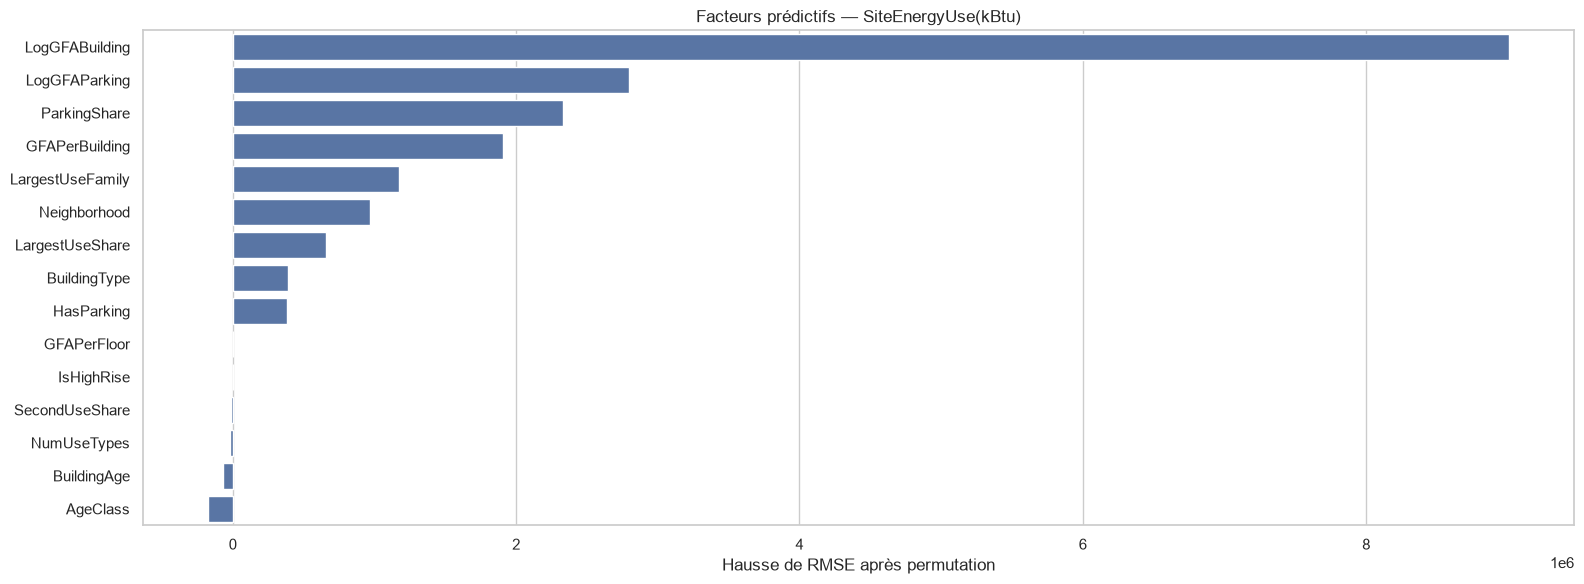

In [11]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold

importances_par_cible = {}
fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 6))
for ax, target_col in zip(np.atleast_1d(axes), TARGETS):
    X_train, _, y_train, _ = splits_modelisation[target_col]
    importances_plis = []
    plis = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for indices_train, indices_validation in plis.split(X_train):
        modele_plis = clone(modeles_retenus[target_col])
        modele_plis.fit(X_train.iloc[indices_train], y_train.iloc[indices_train])
        importance = permutation_importance(
            modele_plis, X_train.iloc[indices_validation], y_train.iloc[indices_validation],
            scoring='neg_root_mean_squared_error', n_repeats=5,
            random_state=RANDOM_STATE, n_jobs=1
        )
        importances_plis.append(importance.importances)
    importances = np.concatenate(importances_plis, axis=1)
    tableau_importance = pd.DataFrame({
        'Variable': X_train.columns,
        'Hausse_RMSE': importances.mean(axis=1),
        'Écart_type': importances.std(axis=1),
    }).sort_values('Hausse_RMSE', ascending=False)
    importances_par_cible[target_col] = tableau_importance
    display(tableau_importance.head(15).round(3))
    sns.barplot(data=tableau_importance.head(15), x='Hausse_RMSE', y='Variable', ax=ax)
    ax.set(title=f'Facteurs prédictifs — {target_col}', xlabel='Hausse de RMSE après permutation', ylabel='')
plt.tight_layout()
plt.show()